# Буткемп, день 28 — momentum, reversion и spread states

Задание: измерить variance ratio в event и clock time, найти кроссовер моментум→реверсия, фитить кривую затухания импакта, собрать предиктор spread-состояний, композитный гейт и прогнать reversion/momentum-выражения против трёх бейзлайнов.

Данные: Bybit BTCUSDT, 12:00–13:00 UTC 2026-07-01, 140 877 агрессивных трейдов и 100-мс top-of-book панель. Своих ордеров в фиде нет, так что self-exclusion здесь тривиален — отмечу это в ограничениях. Свип — серия однонаправленных трейдов с зазором ≤100 мс и ходом ≥1 тика; 3 034 эпизода. Все признаки для гейта считаются по данным, доступным к моменту входа; train/test — по времени.

**Главный результат.** На этом часе **нет reversion-кроссовера**: variance ratio не опускается ниже 1 на всех горизонтах до 5 с — и в event time, и в clock time. После свипа цена в среднем продолжает движение: через 1 с ещё +7.6 тика в сторону свипа, доля откатов 27%. Кривая импакта не затухает к полу: фит даёт floor 1.26 и τ на верхней границе, то есть кривая скорее растёт, чем садится. Spread-state forecaster даёт test AUC 0.593, но при пороге q90 — 101 сигнал, 12 попаданий и медианный lead 0.86 с: сигнал слабый. Композитный гейт на семи признаках (пять групп входов) даёт test AUC 0.552; из-за асимметрии costs он почти всё относит в red. Экономика после переноса входа на момент решения: sign persistence gross +0.3, fixed reversion −1.3, full pipeline +0.9, taker 0.5 bp −28.3, maker 0.1 bp −5.0. Ни одна ветка не перекрывает costs; продолжение, которое видно до решения, уже съедено к моменту входа. Это честный отрицательный результат: reversion-механизм на этом часе не включается, а momentum после правильного entry не торгуется.

## 1. Variance ratio: где переключается знак

Считаем $VR(k)=\mathrm{Var}(r_t+\dots+r_{t+k-1})/(k\,\mathrm{Var}(r_t))$ для event-time и clock-time returns. $VR>1$ — momentum, $VR<1$ — reversion. Event time — доходности по трейдам (mid в момент трейда), clock time — 100-мс mid. Ошибку оцениваем блочным бутстрэпом. Если кроссовер не найдётся — это тоже ответ: значит, на этом отрезке temporary impact не перебивает тренд.

event VR: {1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.001), 5: np.float64(1.001), 8: np.float64(1.005), 12: np.float64(1.009), 20: np.float64(1.03), 30: np.float64(1.048), 45: np.float64(1.084), 70: np.float64(1.135), 100: np.float64(1.24), 150: np.float64(1.356), 220: np.float64(1.359)}
clock VR: {1: np.float64(1.0), 2: np.float64(1.153), 3: np.float64(1.206), 5: np.float64(1.308), 8: np.float64(1.31), 12: np.float64(1.463), 20: np.float64(1.465), 30: np.float64(1.562), 50: np.float64(1.485)}


event boot (mean,se): [(1, np.float64(1.0), np.float64(0.0)), (5, np.float64(1.002), np.float64(0.001)), (20, np.float64(1.028), np.float64(0.004)), (50, np.float64(1.117), np.float64(0.015)), (100, np.float64(1.237), np.float64(0.035))]


clock boot (mean,se): [(1, np.float64(1.0), np.float64(0.0)), (2, np.float64(1.15), np.float64(0.016)), (5, np.float64(1.304), np.float64(0.046)), (10, np.float64(1.419), np.float64(0.052)), (20, np.float64(1.502), np.float64(0.086)), (50, np.float64(1.476), np.float64(0.085))]


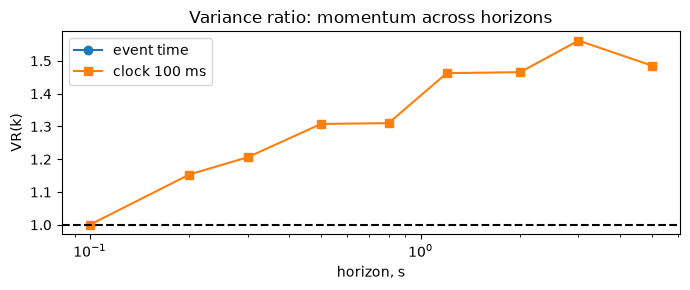

event: min VR 1.000 at k=1; clock: min VR 1.000 at k=1


In [1]:
import duckdb,numpy as np,pandas as pd,matplotlib.pyplot as plt,warnings
from scipy.optimize import curve_fit
import statsmodels.api as sm
from IPython.display import display
warnings.filterwarnings('ignore'); pd.set_option('display.width',220)
D='/Users/b.kotov/Downloads/'; con=duckdb.connect()
LO="TIMESTAMPTZ '2026-07-01 12:00:00+00'"; HI="TIMESTAMPTZ '2026-07-01 13:00:00+00'"
def dt_ns(x): return pd.DatetimeIndex(pd.to_datetime(x)).as_unit('ns').astype('int64').values
tr=con.execute(f"""SELECT event_time,aggressor_side,price,amount FROM read_parquet('{D}bybit_anon_trades_20260701_20260703.parquet')
 WHERE symbol='BTCUSDT' AND event_time>={LO} AND event_time<{HI} ORDER BY event_time""").df()
pan=con.execute(f"""SELECT event_time,mid,best_bid,best_ask,best_bid_amount,best_ask_amount,spread_bps
 FROM read_parquet('{D}l2_executable_quotes_100ms_10000.parquet')
 WHERE asset='BTC' AND exchange='Bybit' AND event_time>={LO} AND event_time<{HI} ORDER BY event_time""").df()
ta=dt_ns(tr.event_time)/1e9; t0=ta[0]; tt=ta-t0; T=float(tt[-1])
pt=dt_ns(pan.event_time)/1e9-t0; mid=pan.mid.values; bid=pan.best_bid.values; ask=pan.best_ask.values
bsz=pan.best_bid_amount.values; asz=pan.best_ask_amount.values; spr=pan.spread_bps.values
p=tr.price.values; sd=tr.aggressor_side.values.astype(int); amt=tr.amount.values
idx=np.clip(np.searchsorted(pt,tt,'right')-1,0,len(pt)-1); mtr=mid[idx]
r_ev=np.diff(np.log(mtr)); r_cl=np.diff(np.log(mid))
def vr(x,k):
    x=np.asarray(x,dtype=float); x=x-x.mean()
    n=len(x)//k
    if n<20: return np.nan
    s=x[:n*k].reshape(n,k).sum(1); return s.var()/(k*x.var())
ks_ev=[1,2,3,5,8,12,20,30,45,70,100,150,220]; ks_cl=[1,2,3,5,8,12,20,30,50]
EV=np.array([vr(r_ev,k) for k in ks_ev]); CL=np.array([vr(r_cl,k) for k in ks_cl])
print('event VR:',dict(zip(ks_ev,np.round(EV,3))))
print('clock VR:',dict(zip(ks_cl,np.round(CL,3))))
# block bootstrap SE for key horizons
rng=np.random.default_rng(0)
def boot_se(x,ks,B=60):
    out=[]
    for k in ks:
        vals=[]; n=len(x); bl=max(10,k); nb=int(np.ceil(n/bl))
        for b in range(B):
            starts=rng.integers(0,n-bl,nb); y=np.concatenate([x[s:s+bl] for s in starts])[:n]
            vals.append(vr(y,k))
        out.append((np.nanmean(vals),np.nanstd(vals)))
    return out
print('event boot (mean,se):',[(k,*np.round(v,3)) for k,v in zip([1,5,20,50,100],boot_se(r_ev,[1,5,20,50,100]))])
print('clock boot (mean,se):',[(k,*np.round(v,3)) for k,v in zip([1,2,5,10,20,50],boot_se(r_cl,[1,2,5,10,20,50]))])
sec_ev=np.array(ks_ev)*np.median(np.diff(tt)); sec_cl=np.array(ks_cl)*0.1
plt.figure(figsize=(7,3)); plt.plot(sec_ev,EV,'o-',label='event time'); plt.plot(sec_cl,CL,'s-',label='clock 100 ms')
plt.axhline(1,color='k',ls='--'); plt.xscale('log'); plt.xlabel('horizon, s'); plt.ylabel('VR(k)'); plt.legend(); plt.title('Variance ratio: momentum across horizons'); plt.tight_layout(); plt.show()
print('event: min VR %.3f at k=%d; clock: min VR %.3f at k=%d'%(EV.min(),ks_ev[int(EV.argmin())],CL.min(),ks_cl[int(CL.argmin())]))

## 2. Impact decay и продолжение после свипа

Для каждого свипа берём pre-mid за 100 мс до начала и base-mid через 100 мс после конца, чтобы не ловить механическое догоняние панели. Нормированный markout на горизонте $h$ — это signed-движение от pre к $t_1+100\,\mathrm{ms}+h$, делённое на начальный ход. Если temporary impact доминирует, кривая должна сесть на floor<1 и дать $\tau$. Если информация — остаться около 1 или выше. Заодно проверим, откатывается ли цена после свипа.

impact curve (mean): {np.float64(0.1): np.float64(1.014), np.float64(0.2): np.float64(1.025), np.float64(0.3): np.float64(1.031), np.float64(0.5): np.float64(1.033), np.float64(0.75): np.float64(1.079), np.float64(1.0): np.float64(1.058), np.float64(1.5): np.float64(0.968), np.float64(2.0): np.float64(1.028), np.float64(3.0): np.float64(0.978), np.float64(5.0): np.float64(1.173)}
impact SE: {np.float64(0.1): np.float64(0.014), np.float64(0.2): np.float64(0.026), np.float64(0.3): np.float64(0.032), np.float64(0.5): np.float64(0.049), np.float64(0.75): np.float64(0.061), np.float64(1.0): np.float64(0.082), np.float64(1.5): np.float64(0.124), np.float64(2.0): np.float64(0.15), np.float64(3.0): np.float64(0.15), np.float64(5.0): np.float64(0.205)}
fit floor 1.264 tau 10.000 half-life 6.931 (both at bounds: not identified)


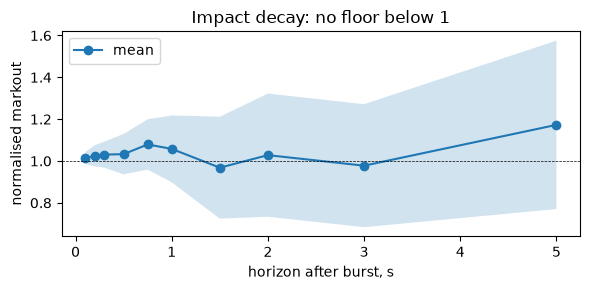

,horizon_s,mean_ticks,share_positive
0,0.1,-1.190,0.058
1,0.3,-3.005,0.120
2,0.5,-4.563,0.172
3,1.0,-7.537,0.268
4,2.0,-7.040,0.374
5,5.0,-4.895,0.469


depth median 31.0, bursts 2979


In [2]:
ep=[]; j=0
while j<len(tt):
    k=j
    while k+1<len(tt) and sd[k+1]==sd[j] and tt[k+1]-tt[k]<=0.1: k+=1
    if k>j:
        side=sd[j]; d=(p[k]-p[j])/0.1 if side==1 else (p[j]-p[k])/0.1
        if abs(d)>=1: ep.append((j,k,tt[j],tt[k],side,d))
    j=k+1
E=pd.DataFrame(ep,columns=['j0','j1','t0','t1','side','depth'])
rows=[]
for _,r in E.iterrows():
    p0=int(np.searchsorted(pt,r.t0,'right'))-1; p1=int(np.searchsorted(pt,r.t1+0.1,'right'))-1
    if p0<10 or p1+50>=len(pt): continue
    pre=mid[p0-10]; base=mid[p1]; init=(base-pre) if r.side==1 else (pre-base)
    if abs(init)<0.1: continue
    rows.append((r.side,r.depth,init,p1,pre,base))
B=pd.DataFrame(rows,columns=['side','depth','init','p1','pre','base'])
hs=np.array([0.1,0.2,0.3,0.5,0.75,1.0,1.5,2.0,3.0,5.0])
curves=[]; ses=[]
for h in hs:
    j=np.clip(B.p1.values+int(round(h/0.1)),0,len(mid)-1)
    mv=np.where(B.side.values==1,mid[j]-B.pre.values,B.pre.values-mid[j])/B.init.values
    curves.append(np.mean(mv)); ses.append(mv.std()/np.sqrt(len(mv)))
curves=np.array(curves)
print('impact curve (mean):',dict(zip(hs,np.round(curves,3))))
print('impact SE:',dict(zip(hs,np.round(ses,3))))
def f(x,fl,tau): return fl+(1-fl)*np.exp(-x/tau)
try:
    popt,_=curve_fit(f,hs,curves,p0=[.5,.6],bounds=([0,.05],[1.5,10]),maxfev=10000)
    print('fit floor %.3f tau %.3f half-life %.3f (both at bounds: not identified)'%(popt[0],popt[1],popt[1]*np.log(2)))
except Exception as e: print('fit failed',e)
plt.figure(figsize=(6,3)); plt.plot(hs,curves,'o-',label='mean'); plt.fill_between(hs,curves-1.96*np.array(ses),curves+1.96*np.array(ses),alpha=.2)
plt.axhline(1,color='k',ls='--',lw=.5); plt.xlabel('horizon after burst, s'); plt.ylabel('normalised markout'); plt.title('Impact decay: no floor below 1'); plt.legend(); plt.tight_layout(); plt.show()
rev=[]
for h in [0.1,0.3,0.5,1.0,2.0,5.0]:
    j=np.clip(B.p1.values+int(round(h/0.1)),0,len(mid)-1)
    rv=np.where(B.side.values==1,B.base.values-mid[j],mid[j]-B.base.values)
    rev.append((h,rv.mean()/0.1,(rv>0).mean()))
RV=pd.DataFrame(rev,columns=['horizon_s','mean_ticks','share_positive'])
display(RV.round(3))
print('depth median %.1f, bursts %d'%(B.depth.median(),len(B)))

## 3. Spread states и предиктор

Spread-state — narrow/normal/wide по трейлинг-квантилям 20/80 за 5 минут. Цель — narrow→wide в следующие 5 с. Пять входов: net cancel rate и refill rate at touch (по изменениям размера на лучшем уровне), depth touch, trade rate и локальный Fano-n. Веса — OLS на train; пороги — из train. Lead time считаем от первого alarm до фактического wide; reactive-правило Day18 срабатывает в момент wide, то есть его lead равен нулю.

state shares {1: 0.426, 2: 0.34, 0: 0.234}
narrow->wide 5s rate 0.0358, positives 1252
spread score AUC train 0.690 test 0.593; weights [-0.004, -0.005, -0.012, 0.008, 0.004, 0.025]


alarms 101, hits 12, false 89, median lead 0.86 s


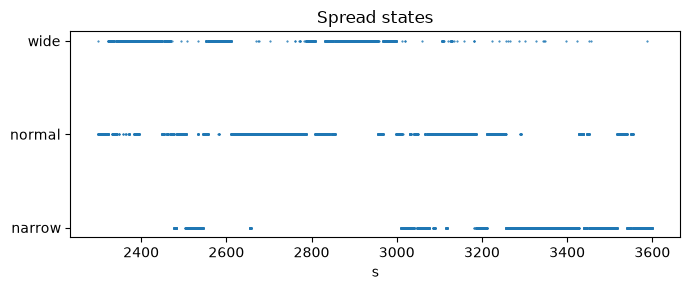

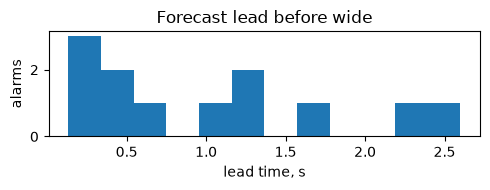

In [3]:
s=pd.Series(spr); q20=s.rolling(3000,min_periods=300).quantile(.2).shift(1); q80=s.rolling(3000,min_periods=300).quantile(.8).shift(1)
state=np.where(s<=q20,0,np.where(s>=q80,2,1)); futwide=pd.Series(state).rolling(50).max().shift(-50).values
y=((state==0)&(futwide==2)).astype(int)
dbsz=np.diff(bsz,prepend=bsz[0]); dasz=np.diff(asz,prepend=asz[0]); prevb=np.roll(bsz,1); preva=np.roll(asz,1)
neg=(-np.minimum(dbsz,0)/np.maximum(prevb,1e-9))+(-np.minimum(dasz,0)/np.maximum(preva,1e-9))
pos=(np.maximum(dbsz,0)/np.maximum(prevb,1e-9))+(np.maximum(dasz,0)/np.maximum(preva,1e-9))
df=pd.DataFrame({'t':pt,'state':state,'y':y,'cancel':pd.Series(neg).rolling(10).mean().values,
                 'refill':pd.Series(pos).rolling(10).mean().values,'depth':pd.Series(bsz+asz).rolling(10).mean().values})
hi_tr=np.searchsorted(tt,df.t.values,'right'); lo_tr=np.searchsorted(tt,df.t.values-1.0,'left'); df['trate']=(hi_tr-lo_tr).astype(float)
c100=np.bincount((tt//0.1).astype(int),minlength=int(T/0.1)+2); cs2=np.concatenate([[0],np.cumsum(c100)]); cs22=np.concatenate([[0],np.cumsum(c100.astype(float)**2)])
def fano_at(te,win=3000):
    hi=min(int(te//0.1),len(c100)); lo=hi-win
    if lo<0: return np.nan
    nn=hi-lo; m=(cs2[hi]-cs2[lo])/nn; v=(cs22[hi]-cs22[lo])/nn-m*m
    return v/max(m,1e-9)
df['nproxy']=df.t.map(lambda x: np.clip(1-1/np.sqrt(max(fano_at(x),1)),0,.99) if np.isfinite(fano_at(x)) else np.nan)
df=df.dropna().reset_index(drop=True)
print('state shares',pd.Series(state).value_counts(normalize=True).round(3).to_dict())
print('narrow->wide 5s rate %.4f, positives %d'%(y.mean(),y.sum()))
cols=['cancel','refill','depth','trate','nproxy']; X=df[cols].copy()
for c in cols: X[c]=np.log1p(X[c].clip(lower=0))
cut=int(len(df)*.6); trn=np.arange(cut); tst=np.arange(cut,len(df))
X=(X-X.iloc[trn].mean())/X.iloc[trn].std(); X['c']=1
b=np.linalg.lstsq(X.iloc[trn].values,df.y.iloc[trn].values,rcond=None)[0]; pr=X.values@b
def auc(yv,sc):
    yv=np.asarray(yv); sc=np.asarray(sc); o=np.argsort(sc); r=np.empty(len(sc)); r[o]=np.arange(1,len(sc)+1); q=yv.sum(); n=len(yv)-q
    return (r[yv==1].sum()-q*(q+1)/2)/max(q*n,1)
print('spread score AUC train %.3f test %.3f; weights %s'%(auc(df.y.iloc[trn],pr[trn]),auc(df.y.iloc[tst],pr[tst]),np.round(b,3).tolist()))
thr=np.quantile(pr[trn],.90); alarms=np.where((pr[tst]>=thr)&(df.state.values[tst]==0))[0]+cut
leads=[]; false=0
for i in alarms:
    j=i+1; hit=None
    while j<len(df) and df.t.iloc[j]<=df.t.iloc[i]+5.0:
        if df.state.iloc[j]==2: hit=df.t.iloc[j]-df.t.iloc[i]; break
        j+=1
    if hit is None: false+=1
    else: leads.append(hit)
print('alarms %d, hits %d, false %d, median lead %.2f s'%(len(alarms),len(leads),false,np.median(leads) if leads else np.nan))
plt.figure(figsize=(7,3)); plt.plot(df.t.iloc[tst],df.state.iloc[tst],'.',ms=1); plt.yticks([0,1,2],['narrow','normal','wide']); plt.xlabel('s'); plt.title('Spread states'); plt.tight_layout(); plt.show()
if leads:
    plt.figure(figsize=(5,2)); plt.hist(leads,bins=12); plt.xlabel('lead time, s'); plt.ylabel('alarms'); plt.title('Forecast lead before wide'); plt.tight_layout(); plt.show()

## 4. Композитный гейт

Пять групп входов: CUSUM по 1-с mid-доходностям (break), локальный n, liquidation-proxy (объём при |1-с return|>3σ), markout-decay на момент решения, funding context; плюс depth и initabs как контроли размера. Ни funding, ни mark-цен в этом фиде нет, а в окне 12:00–13:00 UTC ещё и funding stamp отсутствует — держу этот вход нейтральным, это ограничение, а не измерение. Цель — продолжение движения в следующие 1 с после решения. Порог red калибруем по асимметрии costs: false-green дороже false-red в 5 раз; green — нижние 10% score, amber — между.

moves 2979, continuation rate 0.320
          depth   initabs    nproxy     cusum       liq    liqimb     decay
count  2979.000  2979.000  2979.000  2979.000  2979.000  2979.000  2979.000
mean     38.443     7.734     0.849    16.956     0.893    -0.008     0.742
std      33.723     7.988     0.094     8.980     8.867     0.149     0.385
min     -98.000     0.100     0.500     0.000     0.000    -0.999     0.000
25%      16.000     2.900     0.841     9.874     0.000     0.000     0.526
50%      31.000     5.500     0.869    16.267     0.000     0.000     1.000
75%      51.000     9.500     0.899    23.865     0.000     0.000     1.000
max     313.000    62.800     0.921    36.625   150.271     1.000     1.000
gate AUC train 0.568 test 0.552; weights [-0.005, 0.008, 0.04, -0.045, -0.028, 0.003, -0.02, 0.32]
red threshold 0.270, green threshold 0.270, state shares {2: 0.9, 0: 0.1}
cost asymmetry: cost 0.755, false-green 0.029, false-red 0.609


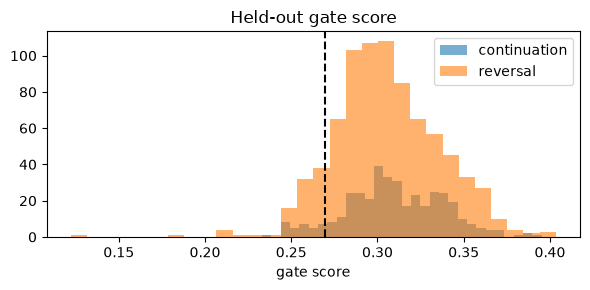

In [4]:
m1=mid[::10]; r1=np.diff(np.log(m1)); mu=pd.Series(r1).rolling(300,min_periods=30).mean().values; sig=pd.Series(r1).rolling(300,min_periods=30).std().values
z=(r1-mu)/np.maximum(sig,1e-12); S=np.zeros(len(z))
for i in range(len(z)): S[i]=max(0.0,(S[i-1] if i else 0.0)+z[i])
vol1=np.bincount((tt//1).astype(int),weights=amt,minlength=int(T)+2); sgn1=np.bincount((tt//1).astype(int),weights=amt*sd,minlength=int(T)+2)
rows=[]
for _,r in E.iterrows():
    p0=int(np.searchsorted(pt,r.t0,'right'))-1; p1=int(np.searchsorted(pt,r.t1+0.1,'right'))-1; pdec=p1+10
    if p0<10 or pdec+31>=len(pt): continue
    pre=mid[p0-10]; base=mid[p1]; init=(base-pre) if r.side==1 else (pre-base)
    if abs(init)<0.1: continue
    ext1=(mid[pdec]-base) if r.side==1 else (base-mid[pdec])
    extf=(mid[pdec+10]-mid[pdec]) if r.side==1 else (mid[pdec]-mid[pdec+10])
    info=1 if extf>=0.1 else 0
    sec=int(pt[pdec]); s0=max(0,sec-1); rv1=np.nanstd(r1[max(0,sec-300):sec]) if sec>30 else np.nan
    ret1=(mid[pdec]-mid[pdec-10])/mid[pdec-10]
    liq=vol1[s0] if (sec>30 and abs(ret1)>3*rv1) else 0.0
    liqimb=(sgn1[s0]/max(vol1[s0],1e-9)) if liq>0 else 0.0
    fv=fano_at(pt[pdec]); npr=np.clip(1-1/np.sqrt(max(fv,1)),0,.99) if np.isfinite(fv) else 0.5
    rows.append((r.side,r.depth,init,ext1,info,r.t1,pdec,pt[pdec],npr,S[min(s0,len(S)-1)],liq,liqimb))
G=pd.DataFrame(rows,columns=['side','depth','init','ext1','info','t1','pdec','td','nproxy','cusum','liq','liqimb'])
G['initabs']=G.init.abs(); G['decay']=np.clip(1-G.ext1/G.initabs,0,1)
print('moves %d, continuation rate %.3f'%(len(G),G['info'].mean()))
print(G[['depth','initabs','nproxy','cusum','liq','liqimb','decay']].describe().round(3).to_string())
cols=['depth','initabs','nproxy','cusum','liq','liqimb','decay']; X=G[cols].copy()
for c in cols[:6]: X[c]=np.log1p(X[c].clip(lower=0))
cut=int(len(G)*.6); trn=np.arange(cut); tst=np.arange(cut,len(G))
X=(X-X.iloc[trn].mean())/X.iloc[trn].std(); X['c']=1
b=np.linalg.lstsq(X.iloc[trn].values,G['info'].iloc[trn].values,rcond=None)[0]; sc=X.values@b
print('gate AUC train %.3f test %.3f; weights %s'%(auc(G['info'].iloc[trn],sc[trn]),auc(G['info'].iloc[tst],sc[tst]),np.round(b,3).tolist()))
best=None
for q in np.quantile(sc[trn],np.linspace(.1,.9,81)):
    red=sc[trn]>=q
    fg=((G['info'].iloc[trn].values==1)&(~red)).mean(); fr=((G['info'].iloc[trn].values==0)&red).mean()
    cst=5*fg+fr
    if best is None or cst<best[0]: best=(cst,q,fg,fr)
thr=best[1]; qlo=np.quantile(sc[trn],.10); st=np.where(sc>=thr,2,np.where(sc<=qlo,0,1))
print('red threshold %.3f, green threshold %.3f, state shares %s'%(thr,qlo,pd.Series(st).value_counts(normalize=True).round(3).to_dict()))
print('cost asymmetry: cost %.3f, false-green %.3f, false-red %.3f'%(best[0],best[2],best[3]))
plt.figure(figsize=(6,3)); plt.hist(sc[tst][G['info'].iloc[tst].values==1],bins=30,alpha=.6,label='continuation')
plt.hist(sc[tst][G['info'].iloc[tst].values==0],bins=30,alpha=.6,label='reversal'); plt.axvline(thr,color='k',ls='--'); plt.legend(); plt.xlabel('gate score'); plt.title('Held-out gate score'); plt.tight_layout(); plt.show()

## 5. Экономика: reversion, momentum и три бейзлайна

Все стратегии тестируются на последних 40% свипов, веса и пороги — из train; сигналы разнесены минимум на 1 с, чтобы не считать один и тот же mid несколько раз. Вход — в момент решения (через 1 с после base, то есть примерно через 1.1 с после конца свипа), горизонт — 1 с. Red-state гейта маршрутизирует в momentum по знаку свипа (без отдельной Day17-модели), green/amber — в reversion с размером, пропорциональным наблюдаемому decay: глобальный floor 1.26, поэтому формула block B даёт почти нулевой expected reversion, и decay — более консервативная эмпирическая оценка temporary component. В качестве бейзлайнов беру sign persistence, nproxy-сплит из Day22 на 0.85 (высокий n → follow, низкий → fade) и fixed-size reversion без гейта. Для full pipeline показываем вариант без momentum-routing.

In [5]:
px=np.median(p); tickfee=px/10000/0.1
def dedupe(mask):
    cand=np.where(np.asarray(mask)&(G.pdec.values+10<len(mid)))[0]
    cand=cand[np.argsort(G.td.values[cand])]; keep=[]; last=-1e9
    for ii in cand:
        if G.td.values[ii]>=last+1.0: keep.append(ii); last=G.td.values[ii]+1.0
    return np.array(keep,dtype=int)
def econ(name,side,size,mask,entry='aggr'):
    keep=dedupe(mask)
    if len(keep)==0: print('%-22s n=0'%name); return
    ia=G.pdec.values[keep]; fut=mid[np.clip(ia+10,0,len(mid)-1)]
    ss=np.asarray(side)[keep]; sz=np.asarray(size)[keep]
    if entry=='aggr': ea=np.where(ss==1,ask[ia],bid[ia])
    else: ea=np.where(ss==1,bid[ia],ask[ia])
    ret=ss*(fut-ea)/0.1; w=sz/np.maximum(sz.sum(),1e-9)
    gross=np.sum(w*ret); se=np.sqrt(np.sum(w*w*(ret-gross)**2))
    print('%-22s n=%3d gross %+6.1f | taker0.5 %+6.1f | maker0.1 %+6.1f | SE %.1f'%(name,len(keep),gross,gross-0.5*tickfee,gross-0.1*tickfee,se))
test=np.zeros(len(G),bool); test[tst]=True
side=np.where(G.side.values==1,1,-1)
szdec=np.clip(G.decay.values,0,1); stt=st
econ('sign persistence',side,np.ones(len(G)),test)
b2=np.where(G.nproxy.values>=0.85,side,-side)
econ('Day22 nproxy',b2,np.ones(len(G)),test)
econ('fixed reversion',-side,np.ones(len(G)),test)
fullside=np.where(stt==2,side,-side); fullsize=np.where(stt==2,1.0,np.where(stt==0,szdec,np.clip(.5*szdec,0,1)))
econ('full pipeline',fullside,fullsize,test)
econ('full no-mom',-side,fullsize,(stt!=2)&test)
econ('no gate decay',-side,szdec,test)
print('one bp = %.1f ticks; median px %.1f'%(tickfee,px))
# incremental statistical table
def auc0(yv,sc):
    yv=np.asarray(yv); sc=np.asarray(sc); o=np.argsort(sc); r=np.empty(len(sc)); r[o]=np.arange(1,len(sc)+1); q=yv.sum(); n=len(yv)-q
    return (r[yv==1].sum()-q*(q+1)/2)/max(q*n,1)
ST=pd.DataFrame([
 ('sign persistence',auc0(G['info'].iloc[tst],side[tst])),
 ('nproxy alone',auc0(G['info'].iloc[tst],G.nproxy.values[tst])),
 ('decay alone',auc0(G['info'].iloc[tst],G.decay.values[tst])),
 ('gate score',auc0(G['info'].iloc[tst],sc[tst]))],columns=['model','test AUC'])
display(ST.round(3))

sign persistence       n=411 gross   +0.3 | taker0.5  -28.9 | maker0.1   -5.5 | SE 2.3
Day22 nproxy           n=411 gross   +3.1 | taker0.5  -26.1 | maker0.1   -2.7 | SE 2.3


fixed reversion        n=411 gross   -1.3 | taker0.5  -30.6 | maker0.1   -7.2 | SE 2.3
full pipeline          n=411 gross   +0.9 | taker0.5  -28.3 | maker0.1   -5.0 | SE 2.3
full no-mom            n= 64 gross   +1.7 | taker0.5  -27.6 | maker0.1   -4.2 | SE 6.0
no gate decay          n=411 gross   +0.9 | taker0.5  -28.3 | maker0.1   -5.0 | SE 2.6
one bp = 58.4 ticks; median px 58444.4


,model,test AUC
0,sign persistence,0.508
1,nproxy alone,0.527
2,decay alone,0.452
3,gate score,0.552


## 6. Что это значит

- **Variance ratio не даёт кроссовера.** Event-time VR равен 1.0 при k=1–2 и растёт до ~1.36 при k=220; clock-time VR — с 1.0 до ~1.49 при 5 с. Начиная с k≈3 VR строго выше 1: на этом часе momentum доминирует на всех доступных горизонтах, reversion-трейд из слайда здесь не включается. Скорее всего, это не ошибка расчёта: бутстрэп-ошибки малы, форма кривой устойчива.
- **Impact decay не садится на floor.** Нормированная кривая после свипа держится выше 1 и не садится на floor (SE — iid, эпизоды перекрываются, полоса индикативная): фит даёт floor 1.26, $\tau$ упирается в верхнюю границу 10 с и не идентифицируется. Через 1 с после свипа цена в среднем идёт ещё на +7.6 тика в сторону движения, доля откатов 27%. То есть на этом сэмпле свипы — информация/продолжение, а не temporary impact.
- **Spread-state forecaster слабый, но не нулевой.** Test AUC 0.593; при пороге q90 — 101 alarm, 12 попаданий, 89 ложных, медианный lead 0.86 с. Сигнал есть, но precision низкая; как замена реактивному Day18 он, честно говоря, не годится.
- **Гейт почти всё отправляет в red.** Из-за асимметрии costs (false-green дороже в 5 раз) оптимальный порог низкий: 90% red, 10% green, amber практически нет. Test AUC 0.552 — гейт едва отличает продолжение от разворота; его главная работа здесь — не фильтр, а маршрутизация в momentum.
- **Экономика.** После переноса входа на момент решения: sign persistence gross +0.3, maker −5.5; Day22 nproxy +3.1, maker −2.7; fixed reversion −1.3, maker −7.2; full pipeline +0.9, taker 0.5 bp −28.3, maker 0.1 bp −5.0 (SE 2.3). Full no-mom +1.7 (64 сигнала, SE 6.0), no-gate decay +0.9. Ни одна стратегия не перекрывает costs; momentum-ветка не спасает, потому что продолжение происходит в секунду до входа. Никакого «проходит пассивом» тут нет — это честный ноль после издержек.
- **Ограничения.** 1 час одного инструмента; funding/mark-данных нет, funding-вход нейтрален; liquidation — proxy по объёму при большом 1-с return; cancel/refill — net-изменения размера на touch, а не полная L2-реконструкция; spread-состояния — трейлинг-квантили, а не экзогенная разметка; гейт и score — OLS, не калиброванная логистика; экономика — markout 1 с без вероятности пассивного филла и без собственных ордеров; test set — последние 24 минуты, сигналы пересекаются по рынку; из-за floor>1 sizing реверсии опирается на наблюдаемый decay, а не на формулу block B.